#  Final Results


1. ERM baseline
2. General four-group Group DRO (`identity_any × label`)
3. Christian-targeted Group DRO
4. Muslim-targeted Group DRO
5. LGBTQ-targeted Group DRO
6. Black-targeted Group DRO

In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import os

PROJECT_ROOT = Path("/content/drive/MyDrive/ele680/ele680-civilComments-20261029T191748Z-1-001/ele680-civilComments")
if not PROJECT_ROOT.exists():
    raise FileNotFoundError(PROJECT_ROOT)

os.chdir(PROJECT_ROOT)
print("Project root:", Path.cwd())

sns.set_theme(style="whitegrid")
FIGURE_DIR=Path("figures/results")
FIGURE_DIR.mkdir(parents=True,exist_ok=True)
print("Figures will be saved to:",FIGURE_DIR.resolve())


Figures will be saved to: /content/drive/MyDrive/ele680/ele680-civilComments-20261029T191748Z-1-001/ele680-civilComments/figures/results


In [3]:
RESULTS_ROOT=Path("results")

CANDIDATES={
    "ERM":["erm"],
    "General Group DRO":["group_dro","group_droR"],
    "Christian targeted":["group_dro_christian"],
    "Muslim targeted":["group_dro_muslim"],
    "LGBTQ targeted":["group_dro_lgbtq"],
    "Black targeted":["group_dro_black"],
}

def find_prediction_file(label):
    for folder in CANDIDATES[label]:
        path=RESULTS_ROOT/folder/"test_predictions.csv"
        if path.exists(): return path
    return None

prediction_paths={label:find_prediction_file(label) for label in CANDIDATES}
for label,path in prediction_paths.items():
    print(f"{label:22s}: {path}")

missing=[label for label,path in prediction_paths.items() if path is None]
if missing:
    raise FileNotFoundError(
        "Missing test_predictions.csv for: " + ", ".join(missing) +
        ". Update CANDIDATES with your exact folder names."
    )


ERM                   : results/erm/test_predictions.csv
General Group DRO     : results/group_dro/test_predictions.csv
Christian targeted    : results/group_dro_christian/test_predictions.csv
Muslim targeted       : results/group_dro_muslim/test_predictions.csv
LGBTQ targeted        : results/group_dro_lgbtq/test_predictions.csv
Black targeted        : results/group_dro_black/test_predictions.csv


## Load and validate all prediction files


In [4]:
IDENTITY_COLUMNS=["male","female","LGBTQ","christian","muslim","other_religions","black","white"]

def load_predictions(path):
    df=pd.read_csv(path)
    required={"true_label","prediction"}|set(IDENTITY_COLUMNS)
    missing=required-set(df.columns)
    if missing: raise ValueError(f"{path} missing columns: {sorted(missing)}")
    return df

data={label:load_predictions(path) for label,path in prediction_paths.items()}

erm=data["ERM"]
for label,df in data.items():
    if len(df)!=len(erm): raise ValueError(f"Row count differs for {label}: {len(df)} vs ERM {len(erm)}")
    if "uid" in erm.columns and "uid" in df.columns:
        if set(erm.uid)!=set(df.uid): raise ValueError(f"UID set differs for {label}")
    else:
        if not np.array_equal(erm.true_label.values,df.true_label.values):
            raise ValueError(f"Label order differs for {label}")
print("All prediction files passed basic consistency checks. Test rows:",len(erm))


All prediction files passed basic consistency checks. Test rows: 132730


In [5]:
def align_to_erm(df):
    if "uid" in erm.columns and "uid" in df.columns:
        cols=["uid","prediction"]
        return erm.merge(df[cols],on="uid",how="inner",validate="one_to_one",suffixes=("_erm","_model"))
    out=erm.copy().rename(columns={"prediction":"prediction_erm"})
    out["prediction_model"]=df["prediction"].values
    return out

def group_table(df):
    rows=[]
    for identity in IDENTITY_COLUMNS:
        vals=np.asarray(df[identity])
        labels=np.asarray(df["true_label"])
        preds=np.asarray(df["prediction"])
        for y,name in [(0,"non-toxic"),(1,"toxic")]:
            mask=(vals>=0.5)&(labels==y)
            n=int(mask.sum())
            acc=np.nan if n==0 else accuracy_score(labels[mask],preds[mask])
            rows.append({"identity":identity,"label":y,"label_name":name,"n":n,"accuracy":acc})
    return pd.DataFrame(rows)

def overall_and_worst(df):
    overall=accuracy_score(df.true_label,df.prediction)
    groups=group_table(df)
    worst=float(groups.accuracy.dropna().min())
    return overall,worst,groups


## ERM vs General Four-Group Group DRO


,Method,Metric,Accuracy
0,ERM,Average accuracy,0.922738
1,ERM,Worst-group accuracy,0.484051
2,Group DRO,Average accuracy,0.844037
3,Group DRO,Worst-group accuracy,0.651492


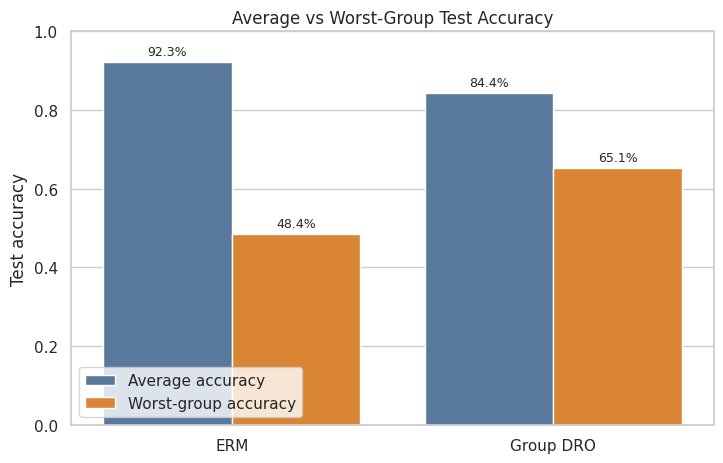

Saved: /content/drive/MyDrive/ele680/ele680-civilComments-20261029T191748Z-1-001/ele680-civilComments/figures/results/figure1_average_vs_worst_group.png


In [6]:
erm_acc,erm_worst,erm_groups=overall_and_worst(data["ERM"])
gdro_acc,gdro_worst,gdro_groups=overall_and_worst(data["General Group DRO"])

main=pd.DataFrame({
    "Method":["ERM","ERM","Group DRO","Group DRO"],
    "Metric":["Average accuracy","Worst-group accuracy","Average accuracy","Worst-group accuracy"],
    "Accuracy":[erm_acc,erm_worst,gdro_acc,gdro_worst]
})

display(main)

plt.figure(figsize=(7.4,4.8))
ax=sns.barplot(data=main,x="Method",y="Accuracy",hue="Metric",palette=["#4C78A8","#F58518"])
for container in ax.containers:
    ax.bar_label(container,labels=[f"{v.get_height()*100:.1f}%" for v in container],padding=3,fontsize=9)
plt.ylim(0,1)
plt.xlabel(""); plt.ylabel("Test accuracy")
plt.title("Average vs Worst-Group Test Accuracy")
plt.legend(title="",loc="lower left")
plt.tight_layout()
fig1=FIGURE_DIR/"figure1_average_vs_worst_group.png"
plt.savefig(fig1,dpi=300,bbox_inches="tight")
plt.show()
print("Saved:",fig1.resolve())


## Four Targeted Group DRO Models



In [7]:
TARGETS={
    "Christian targeted":"christian",
    "Muslim targeted":"muslim",
    "LGBTQ targeted":"LGBTQ",
    "Black targeted":"black",
}

rows=[]
for model_label,identity in TARGETS.items():
    target_df=data[model_label]
    if "uid" in erm.columns and "uid" in target_df.columns:
        aligned=erm.merge(
            target_df[["uid","prediction"]].rename(columns={"prediction":"target_prediction"}),
            on="uid",how="inner",validate="one_to_one"
        ).rename(columns={"prediction":"erm_prediction"})
    else:
        aligned=erm.copy().rename(columns={"prediction":"erm_prediction"})
        aligned["target_prediction"]=target_df.prediction.values

    for y,label_name in [(0,"Non-toxic"),(1,"Toxic")]:
        subset=aligned[(aligned[identity]>=0.5)&(aligned.true_label==y)]
        if len(subset)==0: continue
        rows.extend([
            {"Identity":identity if identity!="LGBTQ" else "LGBTQ","Label":label_name,"Method":"ERM","Accuracy":accuracy_score(subset.true_label,subset.erm_prediction),"n":len(subset)},
            {"Identity":identity if identity!="LGBTQ" else "LGBTQ","Label":label_name,"Method":"Targeted Group DRO","Accuracy":accuracy_score(subset.true_label,subset.target_prediction),"n":len(subset)},
        ])

target_results=pd.DataFrame(rows)
target_results["Identity"]=target_results["Identity"].replace({"christian":"Christian","muslim":"Muslim","black":"Black"})
display(target_results.round(4))


,Identity,Label,Method,Accuracy,n
0,Christian,Non-toxic,ERM,0.9692,12050
1,Christian,Non-toxic,Targeted Group DRO,0.9154,12050
2,Christian,Toxic,ERM,0.4841,1254
3,Christian,Toxic,Targeted Group DRO,0.6794,1254
4,Muslim,Non-toxic,ERM,0.9137,5283
5,Muslim,Non-toxic,Targeted Group DRO,0.8325,5283
6,Muslim,Toxic,ERM,0.5334,1616
7,Muslim,Toxic,Targeted Group DRO,0.6399,1616
8,LGBTQ,Non-toxic,ERM,0.8954,3193
9,LGBTQ,Non-toxic,Targeted Group DRO,0.8155,3193


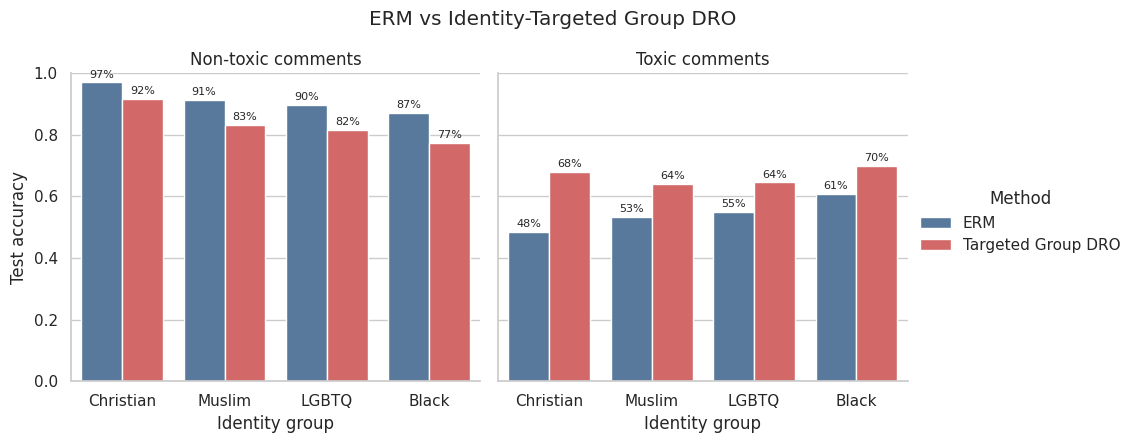

Saved: /content/drive/MyDrive/ele680/ele680-civilComments-20261029T191748Z-1-001/ele680-civilComments/figures/results/figure2_targeted_group_dro.png


In [8]:
g=sns.catplot(
    data=target_results,
    x="Identity",y="Accuracy",hue="Method",col="Label",
    kind="bar",height=4.5,aspect=1.05,
    palette={"ERM":"#4C78A8","Targeted Group DRO":"#E45756"},
    sharey=True
)
g.set_axis_labels("Identity group","Test accuracy")
g.set_titles("{col_name} comments")
g.set(ylim=(0,1))
for ax in g.axes.flat:
    for container in ax.containers:
        ax.bar_label(container,labels=[f"{v.get_height()*100:.0f}%" for v in container],padding=2,fontsize=8)
g.fig.subplots_adjust(top=0.84)
g.fig.suptitle("ERM vs Identity-Targeted Group DRO")
fig2=FIGURE_DIR/"figure2_targeted_group_dro.png"
g.savefig(fig2,dpi=300,bbox_inches="tight")
plt.show()
print("Saved:",fig2.resolve())


In [9]:
main.to_csv(FIGURE_DIR/"figure1_values.csv",index=False)
target_results.to_csv(FIGURE_DIR/"figure2_values.csv",index=False)
print("Saved figure values for traceability.")


Saved figure values for traceability.
